# 12. Timbral grouping of the zones and musical map of the stone (exploratory)

The 24 zones were chosen on purpose, most of them near the edge. This notebook asks (1) whether the zones form
**timbre groups** and (2) what each zone offers to someone who wants to **play** the stone: which note dominates, how
long it lasts and how clean the sound is. It is an exploratory analysis. The groups and the map come from the
characterisation set (notebook 01, section 1.3) and are checked with the validation recordings (section 12.6).

**Inputs:** `intermediate/features.csv` (01), `tables/t04_modal_amplitude_per_zone.csv` and
`t04_zone_coordinates.csv` (04), `tables/t06_mode_table.csv` (06). **Outputs:** `tables/t12_zone_groups.csv`,
`tables/t12_musical_map.csv`, `tables/t12_group_validation.csv`, `figures/fig12a_grouping.png`,
`figures/fig12b_groups_notes_map.png`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

import matplotlib.image as mpimg
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram
from scipy.spatial.distance import squareform
from sklearn.metrics import silhouette_score, adjusted_rand_score as ARI
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict
warnings.filterwarnings("ignore")
F_all = pd.read_csv(C.INTERMEDIATE / "features.csv")
F = F_all[F_all.set == "characterisation"].reset_index(drop=True)     # characterisation set
F_val = F_all[F_all.set == "validation"].reset_index(drop=True)       # validation recordings
amp = pd.read_csv(C.TABLES / "t04_modal_amplitude_per_zone.csv").set_index("zone")
geo = pd.read_csv(C.TABLES / "t04_zone_coordinates.csv").set_index("zone")
modes = pd.read_csv(C.TABLES / "t06_mode_table.csv")
K = 3                     # number of groups (sections 12.2–12.3)

## 12.1 Mean timbre of each zone and hierarchical clustering

Each zone is summarised by the mean of its 15 spectral features (centroid, bandwidth, MFCC 0–12), standardised across
zones. The zones are clustered with Ward's method. The **silhouette** coefficient measures how well separated the
groups are (1 = sharp groups; close to 0 = no clear groups).

In [2]:
def means(d):
    m = d.groupby("zone")[C.RF_FEATURES].mean(); return (m - m.mean()) / m.std()
Z = means(F); zones = Z.index
ward = lambda X, k: fcluster(linkage(X, "ward"), k, "maxclust")
sil = pd.Series({k: silhouette_score(Z, ward(Z.values, k)) for k in range(2, 9)}, name="silhouette")
print("Silhouette by number of groups:", sil.round(3).to_dict())

Silhouette by number of groups: {2: 0.17, 3: 0.153, 4: 0.116, 5: 0.114, 6: 0.123, 7: 0.14, 8: 0.15}


## 12.2 Stability of the groups

The clustering is repeated (a) resampling the strikes of each zone (200 replicates) and (b) leaving out one recording
at a time, and compared with the original by the adjusted Rand index (ARI: 1 = same groups, 0 = chance).

In [3]:
rng = np.random.default_rng(C.SEED); stab = []
for k in range(2, 6):
    ref = ward(Z.values, k); b = []
    for _ in range(200):
        d = F.groupby("zone", group_keys=False).apply(lambda g: g.sample(len(g), replace=True, random_state=int(rng.integers(1e9))))
        b.append(ARI(ref, ward(means(d).loc[zones].values, k)))
    lo = [ARI(ref, ward(means(F[F.file != w]).loc[zones].values, k)) for w in F.file.unique()]
    stab.append({"k": k, "silhouette": sil[k], "ARI_resampling_median": np.median(b), "ARI_resampling_p10": np.percentile(b, 10),
                 "ARI_without_one_recording_median": np.median(lo), "ARI_without_one_recording_min": min(lo)})
stab = pd.DataFrame(stab).set_index("k"); stab.round(2)

,silhouette,ARI_resampling_median,ARI_resampling_p10,ARI_without_one_recording_median,ARI_without_one_recording_min
k,,,,,
2,0.17,0.42,0.20,0.54,0.07
3,0.15,0.39,0.18,0.64,0.15
4,0.12,0.42,0.28,0.49,0.31
5,0.11,0.47,0.29,0.62,0.43


## 12.3 Two other ways of grouping

* **By classifier confusion:** two zones are alike if the random forest (validated leaving one recording out, as in
  notebook 07) often confuses their strikes.
* **By modal content:** amplitudes (dB) of the 13 modes in each zone (notebook 04).

In [4]:
group = ward(Z.values, K)
yp = cross_val_predict(RandomForestClassifier(random_state=C.SEED), F[C.RF_FEATURES], F.zone, groups=F.file,
                       cv=LeaveOneGroupOut(), n_jobs=-1)
cm = pd.crosstab(F.zone, yp).reindex(index=zones, columns=zones, fill_value=0)
P = cm.div(cm.sum(1), axis=0); S = (P + P.T) / 2; np.fill_diagonal(S.values, 1)
g_conf = fcluster(linkage(squareform(1 - S.values, checks=False), "average"), K, "maxclust")
A = amp.drop(columns="modal_purity").loc[zones]; g_modal = ward(((A - A.mean()) / A.std()).values, K)
print(f"Agreement with the timbre grouping (ARI): by confusion {ARI(group, g_conf):.2f}; by modal content {ARI(group, g_modal):.2f}")

Agreement with the timbre grouping (ARI): by confusion 0.16; by modal content 0.05


## 12.4 The groups on the stone

The groups are named A, B, C in order of mean modal purity (fraction of the energy in the 13 global modes) and are
described by the purity and the distance to the edge of their zones.

In [5]:
G = pd.DataFrame({"zone": zones, "group_n": group, "edge_distance_m": geo.edge_distance_m.loc[zones].values,
                  "modal_purity": amp.modal_purity.loc[zones].values})
order = G.groupby("group_n").modal_purity.mean().sort_values(ascending=False).index
NAME = dict(zip(order, ["A", "B", "C"][:K]))
G["group"] = G.group_n.map(NAME)
res = G.groupby("group").agg(zones=("zone", lambda z: ", ".join(map(str, z))), n=("zone", "size"),
                             mean_purity=("modal_purity", "mean"), mean_edge_distance_m=("edge_distance_m", "mean"))
G.drop(columns="group_n").to_csv(C.TABLES / "t12_zone_groups.csv", index=False)
res.round(2)

,zones,n,mean_purity,mean_edge_distance_m
group,,,,
A,"8, 9, 20, 24",4,0.86,0.13
B,"1, 10, 21, 22, 23",5,0.76,0.10
C,"2, 3, 4, 5, 6, 7, 11, 12, 13, 14, 15, 16, 17, ...",15,0.38,0.12


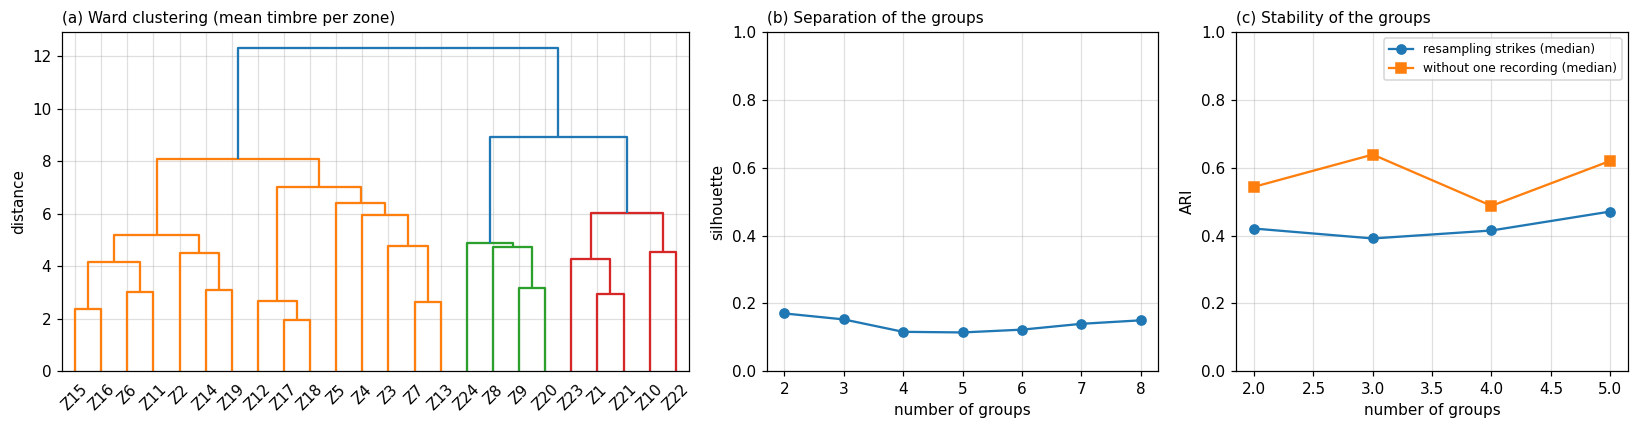

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4), gridspec_kw={"width_ratios": [1.6, 1, 1]})
dendrogram(linkage(Z.values, "ward"), labels=[f"Z{z}" for z in zones], ax=ax[0], color_threshold=sorted(linkage(Z.values, "ward")[:, 2])[-K + 1] - 1e-9)
ax[0].set_title("(a) Ward clustering (mean timbre per zone)", loc="left", fontsize=10); ax[0].set_ylabel("distance")
ax[1].plot(sil.index, sil.values, "o-"); ax[1].set_ylim(0, 1); ax[1].set_xlabel("number of groups"); ax[1].set_ylabel("silhouette")
ax[1].set_title("(b) Separation of the groups", loc="left", fontsize=10)
ax[2].plot(stab.index, stab.ARI_resampling_median, "o-", label="resampling strikes (median)")
ax[2].plot(stab.index, stab.ARI_without_one_recording_median, "s-", label="without one recording (median)")
ax[2].set_ylim(0, 1); ax[2].set_xlabel("number of groups"); ax[2].set_ylabel("ARI"); ax[2].legend(fontsize=8)
ax[2].set_title("(c) Stability of the groups", loc="left", fontsize=10)
plt.tight_layout(); plt.savefig(C.FIGURES / "fig12a_grouping.png", dpi=150, bbox_inches="tight"); plt.show()

## 12.5 Musical map: which note dominates in each zone

The frequencies of the 13 modes are the same over the whole stone; what changes from zone to zone is **which one
dominates**. For each zone the mode with the largest mean amplitude (notebook 04) is taken, with its nearest
equal-tempered note (A4 = 440 Hz) and the deviation in cents, how much it exceeds the second mode (dB), its T60
(notebook 06) and the modal purity. Descriptive criteria (set here, not tuned to the data):

* **clear note:** purity ≥ 0.7 and the dominant mode ≥ 6 dB above the second;
* **two notes:** purity ≥ 0.7 and less than 3 dB between the first two modes (sounds like an interval);
* **dull:** purity < 0.5 (much energy outside the modes, knock-like sound);
* **mixed:** the rest.

In [7]:
NOTE = ["C", "C♯", "D", "D♯", "E", "F", "F♯", "G", "G♯", "A", "A♯", "B"]
def note(f):
    m = 69 + 12 * np.log2(f / 440); n = int(round(m)); return f"{NOTE[n % 12]}{n // 12 - 1}", int(round(100 * (m - n)))
fr = dict(zip(modes["mode"].round(1), modes.f_mean_Hz)); t60 = dict(zip(modes["mode"].round(1), modes.T60_s))
cols = [c for c in amp.columns if c.startswith("A")]
fmap = {c: min(fr, key=lambda m: abs(m - float(c[1:]))) for c in cols}
rows = []
for z in zones:
    a = amp.loc[z, cols].sort_values(ascending=False); m1, m2 = fmap[a.index[0]], fmap[a.index[1]]
    n1, c1 = note(fr[m1]); n2, c2 = note(fr[m2]); pur = amp.modal_purity[z]; dif = a.iloc[0] - a.iloc[1]
    kind = ("dull" if pur < 0.5 else "clear note" if dif >= 6 and pur >= 0.7 else "two notes" if dif < 3 and pur >= 0.7 else "mixed")
    rows.append({"zone": z, "group": G.set_index("zone").group[z], "dominant_mode_Hz": round(fr[m1], 1), "note": n1,
                 "cents": c1, "T60_s": round(t60[m1], 1), "second_mode_Hz": round(fr[m2], 1), "second_note": n2,
                 "advantage_dB": round(dif, 1), "modal_purity": round(pur, 2), "type": kind, "edge_distance_m": geo.edge_distance_m[z]})
MM = pd.DataFrame(rows); MM.to_csv(C.TABLES / "t12_musical_map.csv", index=False)
print("Possible dominant notes:", MM.groupby(["dominant_mode_Hz", "note", "cents"]).zone.apply(list).to_dict())
print(MM["type"].value_counts().to_dict())
MM.drop(columns="edge_distance_m")

Possible dominant notes: {(384.9, 'G4', -32): [2, 6, 14, 15, 17, 19], (599.4, 'D5', 35): [4, 9, 10, 16, 18, 22, 23, 24], (759.2, 'F♯5', 44): [11, 21], (848.8, 'G♯5', 38): [1, 5, 7, 8, 12, 13, 20], (969.5, 'B5', -32): [3]}
{'dull': 10, 'mixed': 6, 'clear note': 4, 'two notes': 4}


,zone,group,dominant_mode_Hz,note,cents,T60_s,second_mode_Hz,second_note,advantage_dB,modal_purity,type
0,1,B,848.8,G♯5,38,2.7,384.9,G4,6.5,0.83,clear note
1,2,C,384.9,G4,-32,2.2,848.8,G♯5,2.6,0.65,mixed
2,3,C,969.5,B5,-32,1.7,384.9,G4,4.3,0.78,mixed
3,4,C,599.4,D5,35,2.0,969.5,B5,1.8,0.59,mixed
4,5,C,848.8,G♯5,38,2.7,759.2,F♯5,2.9,0.47,dull
5,6,C,384.9,G4,-32,2.2,1348.8,E6,2.5,0.75,two notes
6,7,C,848.8,G♯5,38,2.7,384.9,G4,2.2,0.37,dull
7,8,A,848.8,G♯5,38,2.7,599.4,D5,2.3,0.54,mixed
8,9,A,599.4,D5,35,2.0,384.9,G4,9.9,0.96,clear note
9,10,B,599.4,D5,35,2.0,384.9,G4,2.4,0.99,two notes


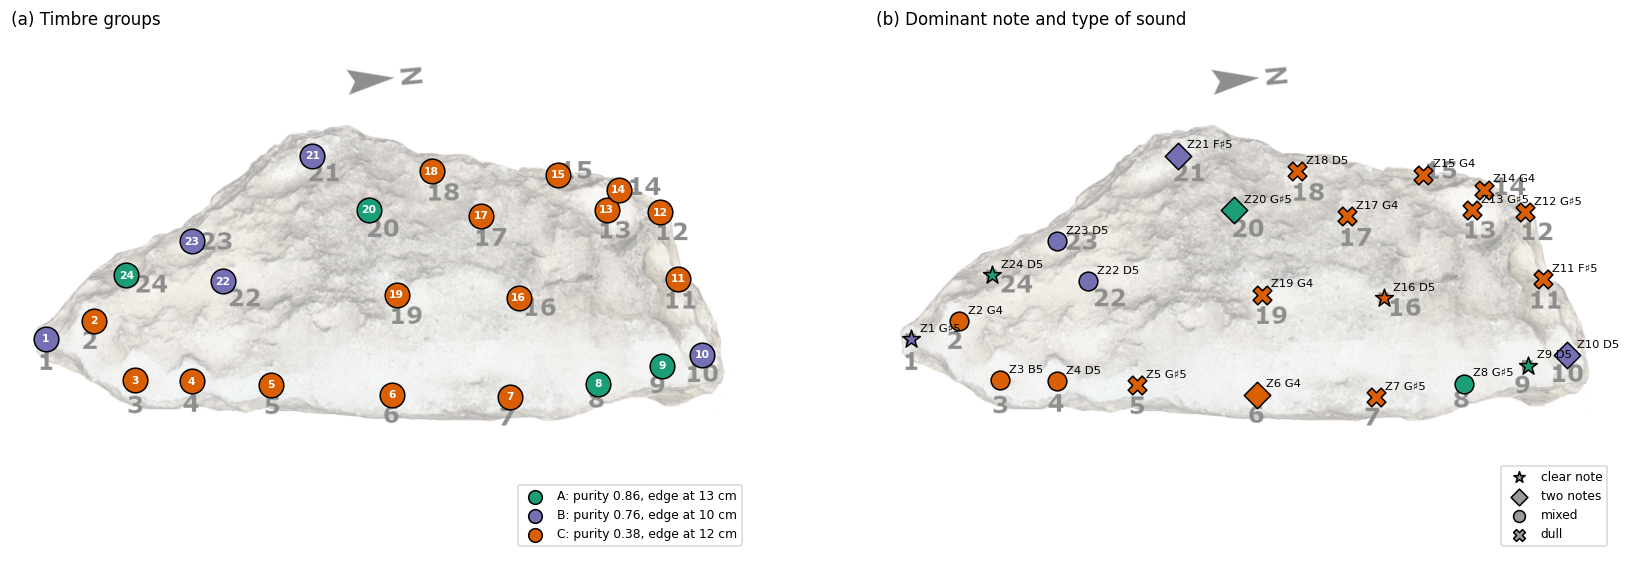

In [8]:
img = mpimg.imread(C.ZONE_MAP)[..., :3]
PIX = {1: (42.5, 379.0), 2: (102.5, 356.5), 3: (153.5, 430.0), 4: (224.0, 431.5), 5: (323.0, 436.0), 6: (473.0, 448.0),
       7: (620.0, 451.0), 8: (729.5, 434.5), 9: (809.0, 412.0), 10: (858.5, 398.5), 11: (828.5, 304.0), 12: (806.0, 221.5),
       13: (740.0, 218.5), 14: (755.0, 193.0), 15: (679.5, 174.5), 16: (630.5, 328.0), 17: (584.0, 226.0), 18: (522.5, 170.5),
       19: (479.0, 323.5), 20: (444.5, 218.5), 21: (374.0, 151.0), 22: (263.0, 307.0), 23: (224.0, 257.5), 24: (143.0, 299.5)}  # notebook 04
COLG = {"A": "#1b9e77", "B": "#7570b3", "C": "#d95f02"}
MARK = {"clear note": "*", "two notes": "D", "mixed": "o", "dull": "X"}
fig, ax = plt.subplots(1, 2, figsize=(16, 5.2))
for a, title in zip(ax, ["(a) Timbre groups", "(b) Dominant note and type of sound"]):
    a.imshow(img, alpha=0.45); a.set_axis_off(); a.set_title(title, loc="left", fontsize=11)
for _, r in G.iterrows():
    x, y = PIX[r.zone]; ax[0].scatter(x, y, s=260, color=COLG[r.group], edgecolor="k", zorder=3)
    ax[0].text(x, y, str(r.zone), ha="center", va="center", fontsize=7, color="w", fontweight="bold", zorder=4)
for g, c in COLG.items(): ax[0].scatter([], [], s=80, color=c, edgecolor="k", label=f"{g}: purity {res.mean_purity[g]:.2f}, edge at {100 * res.mean_edge_distance_m[g]:.0f} cm")
ax[0].legend(loc="lower right", fontsize=8)
for _, r in MM.iterrows():
    x, y = PIX[r.zone]; ax[1].scatter(x, y, s=150, marker=MARK[r["type"]], color=COLG[r.group], edgecolor="k", zorder=3)
    ax[1].annotate(f"Z{r.zone} {r.note}", (x, y), textcoords="offset points", xytext=(6, 5), fontsize=7.5, zorder=4)
for t, mk in MARK.items(): ax[1].scatter([], [], marker=mk, s=60, color="0.6", edgecolor="k", label=t)
ax[1].legend(loc="lower right", fontsize=8)
plt.tight_layout(); plt.savefig(C.FIGURES / "fig12b_groups_notes_map.png", dpi=150, bbox_inches="tight"); plt.show()

## 12.6 Validation with recordings not used in the analysis

The validation recordings cover the 24 zones. Two checks:

1. **Assignment:** the mean timbre of each zone in the validation recordings, standardised with the mean and standard
   deviation of the zones of the characterisation set, is assigned to the group whose centre (in the characterisation
   set) is closest. The number of zones that fall in their own group is counted; chance is estimated by shuffling the
   groups between the zones (5000 times).
2. **Independent clustering:** Ward clustering is repeated with the validation data only and compared with the
   original (ARI).

In [9]:
gz = pd.Series(group, index=zones)
mp = F.groupby("zone")[C.RF_FEATURES].mean()
Zv = (F_val.groupby("zone")[C.RF_FEATURES].mean() - mp.mean()) / mp.std()
centres = Z.groupby(group).mean()
assigned = pd.Series([centres.index[np.argmin(((centres.values - z) ** 2).sum(1))] for z in Zv.values], index=Zv.index)
hit = (assigned == gz.loc[Zv.index]).mean()
rng_v = np.random.default_rng(C.SEED)
null = np.array([(assigned.values == rng_v.permutation(gz.values)[np.searchsorted(zones, Zv.index)]).mean() for _ in range(5000)])
ari_val = ARI(gz.loc[Zv.index], ward(means(F_val).loc[Zv.index].values, K))
tv = pd.DataFrame({"zone": Zv.index, "characterisation_group": gz.loc[Zv.index].map(NAME).values, "validation_group": assigned.map(NAME).values})
tv.to_csv(C.TABLES / "t12_group_validation.csv", index=False)
print(f"{len(Zv)} zones with validation data: {hit:.0%} assigned to their own group "
      f"(chance: median {np.median(null):.0%}, 95th percentile {np.percentile(null, 95):.0%}; p = {(1 + (null >= hit).sum()) / (1 + len(null)):.4f})")
print(f"Clustering of the validation data alone against the original (ARI, {len(Zv)} zones): {ari_val:.2f}")
tv.set_index("zone").T

24 zones with validation data: 88% assigned to their own group (chance: median 46%, 95th percentile 58%; p = 0.0002)
Clustering of the validation data alone against the original (ARI, 24 zones): 0.11


zone,1,2,3,4,5,6,7,8,9,10,...,15,16,17,18,19,20,21,22,23,24
characterisation_group,B,C,C,C,C,C,C,A,A,B,...,C,C,C,C,C,A,B,B,B,A
validation_group,B,C,C,B,C,C,C,A,A,B,...,C,C,C,C,C,C,B,B,B,A


## Conclusion

With the characterisation set and its check with the validation recordings:

* **There are no sharp groups.** The silhouette is low (0.11–0.17 for 2 to 8 groups): the timbre changes gradually
  between zones. The three groups used are moderately stable (median ARI 0.39 resampling strikes and 0.64 leaving out
  one recording):
  * **A** (Z8, Z9, Z20, Z24): the purest (86 % of the energy in the modes);
  * **B** (Z1, Z10, Z21, Z22, Z23): intermediate (76 %);
  * **C** (the other 15 zones): the dullest (38 %).
* **The groups are reproduced in recordings not used in the analysis:** 21 of the 24 zones (88 %) fall in their own
  group with the validation recordings (chance: 95th percentile 58 %); clustering the validation data alone gives a low
  agreement (ARI 0.11).
* The groupings by classifier confusion and by modal content hardly agree with the timbre grouping (ARI 0.16 and 0.05).
* **For a musician**, the frequencies are the same over the whole stone and the zone decides which one dominates. Only
  five modes ever dominate: G4 (385 Hz, −32 cents; 6 zones), D5 (599 Hz, +35; 8 zones), F♯5 (759 Hz, +44; 2), G♯5
  (849 Hz, +38; 7) and B5 (970 Hz, −32; 1), all 30–45 cents away from equal temperament. Four zones give a **clear
  note** (G♯5 at Z1; D5 at Z9, Z16 and Z24); four sound like **two notes** (Z6, Z10, Z20, Z21); six are mixed and ten
  are **dull** (purity < 0.5), mostly among Z11–Z19. The notes last about 2–3 s (T60 2.0–3.0 s).
* **Zones recommended for playing:** Z1, Z9, Z16 and Z24 (clear note) and Z6, Z10, Z20 and Z21 (two notes). The dull
  zones are suitable for percussive effects, not for melody.
* **Cautions.** The microphone was 5 cm away, so the amplitudes describe the sound close to the zone; a few metres away
  the mix of modes may differ. The perceived pitch of an inharmonic sound is not always that of the strongest mode: the
  map should be confirmed with a listening test before it is used with musicians.